# Tarea 4: Determinación del número óptimo de grupos mediante el método del codo

> Uriel Aguilar Mauricio

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score


In [71]:
data, meta = arff.loadarff("../data/raw/kc1.arff")

df = pd.DataFrame(data)

### Parte 1. Preparación de los datos
Realizar las actividades necesarias para preparar el conjunto de datos antes de aplicar el algoritmo K-Means.

Como evidencia deberán incluir:
- Vista general del conjunto de datos.
- Descripción de las variables utilizadas.
- Análisis de posibles valores faltantes.
- Justificación del procedimiento de preparación aplicado.

***Vista General del conjunto de datos***

In [72]:
df.head(4)

,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2.0,2.0,2.0,2.0,1.2,1.2,1.2,1.2,1.4,b'false'
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,b'true'
2,83.0,11.0,1.0,11.0,171.0,927.89,0.04,23.04,40.27,21378.61,...,65.0,10.0,6.0,0.0,18.0,25.0,107.0,64.0,21.0,b'true'
3,46.0,8.0,6.0,8.0,141.0,769.78,0.07,14.86,51.81,11436.73,...,37.0,2.0,5.0,0.0,16.0,28.0,89.0,52.0,15.0,b'true'


In [73]:
df.shape

(2109, 22)

***Descripción de los datos utilizados***

- **loc**: lineas de código que nos da el tamaño del modulo
- **v(g)**: Complejidad ciclomatica dando la complejidad de flujo de control
- **v**: Volumen de Halstead qie es el tamaño lógico del programa
- **iv(g)**: Complejidad del diseño que es la complejidad asociada a la interacción entre módulos

In [74]:
variables = [
"loc", # "LOC_TOTAL",
"v(g)", # "CYCLOMATIC_COMPLEXITY",
"v", # "HALSTEAD_VOLUME",
"iv(g)" # "DESIGN_COMPLEXITY"
]


df_x = df[variables].copy()

In [75]:
df_x.describe()

,loc,v(g),v,iv(g)
count,2109.000000,2109.000000,2109.000000,2109.000000
mean,20.372262,2.838028,258.696719,2.546420
std,29.754442,3.900763,516.317605,3.375859
min,1.000000,1.000000,0.000000,1.000000
25%,3.000000,1.000000,8.000000,1.000000
50%,9.000000,1.000000,57.060000,1.000000
75%,24.000000,3.000000,265.930000,3.000000
max,288.000000,45.000000,7918.820000,45.000000


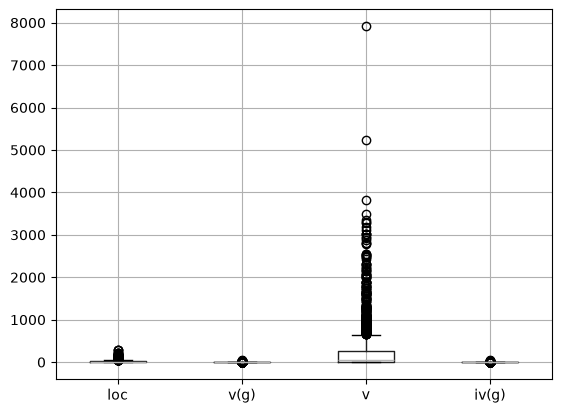

In [76]:
plt.Figure()
df_x.boxplot()
plt.show()

En la descripción de los datos, se puede observar que la complejidad ciclomatica es la que esta predominando.

***Valores faltantes***

In [77]:
faltantes = df_x.isnull().sum().to_frame(name="Valores faltantes")
faltantes["Porcentaje (%)"] = (faltantes["Valores faltantes"] / len(df_x)) * 100

faltantes


,Valores faltantes,Porcentaje (%)
loc,0,0.0
v(g),0,0.0
v,0,0.0
iv(g),0,0.0


No hay valores faltantes, podemos continuar

***Estandarización de los datos***

In [78]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_x)

df_scaled = pd.DataFrame(
    X_scaled,
    columns=variables,
    index=df_x.index
)

df_scaled.head()

,loc,v(g),v,iv(g)
0,-0.647864,-0.368740,-0.498642,-0.339674
1,-0.651226,-0.471309,-0.499223,-0.458191
2,2.105319,2.092900,1.296396,2.504721
3,0.861512,1.323638,0.990097,1.615847
4,0.155568,0.041533,-0.007646,0.134392


In [79]:
df_scaled.describe()

,loc,v(g),v,iv(g)
count,2.109000e+03,2.109000e+03,2.109000e+03,2.109000e+03
mean,-1.347639e-17,5.390557e-17,-2.695278e-17,4.042917e-17
std,1.000237e+00,1.000237e+00,1.000237e+00,1.000237e+00
min,-6.512257e-01,-4.713086e-01,-5.011607e-01,-4.581906e-01
25%,-5.839929e-01,-4.713086e-01,-4.856626e-01,-4.581906e-01
50%,-3.822945e-01,-4.713086e-01,-3.906211e-01,-4.581906e-01
75%,1.219515e-01,4.153313e-02,1.401269e-02,1.343917e-01
max,8.996681e+00,1.081121e+01,1.483959e+01,1.257862e+01


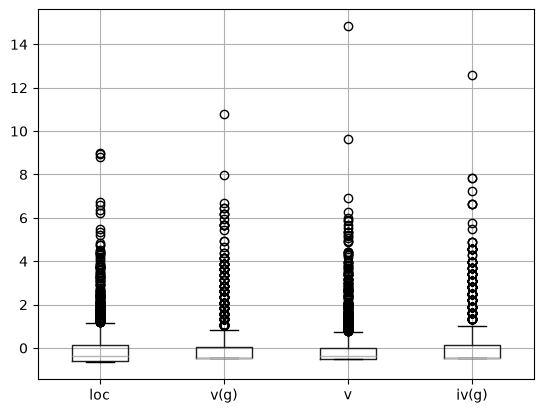

In [80]:
plt.Figure()
df_scaled.boxplot()
plt.show()

Se ha normalizado los datos

### Parte 2. Aplicación del Método del Codo

Aplicar el algoritmo K-Means utilizando distintos valores de K (2-10).

Registrar los resultados obtenidos para cada ejecución y construir los elementos necesarios para aplicar el
Método del Codo.

***Aplicar K-Means con K(2-10)***

In [81]:
valores_k = range(2, 11)
resultados = []

for k in valores_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    resultados.append({
        "K": k,
        "Inercia": kmeans.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels)
    })

resultados = pd.DataFrame(resultados)


***Resultados de todos los K***

In [82]:
resultados.round(3)

,K,Inercia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,3134.673,0.797,0.568,3563.337
1,3,1827.878,0.724,0.648,3806.872
2,4,1329.998,0.684,0.744,3748.913
3,5,1047.195,0.653,0.765,3711.352
4,6,888.216,0.585,0.825,3574.140
5,7,749.805,0.574,0.830,3591.243
6,8,665.367,0.563,0.891,3505.283
7,9,599.671,0.555,0.923,3430.277
8,10,545.088,0.556,0.942,3376.218


***Metodo del Codo***

El Método del Codo se interpreta observando en el punto donde la disminución de la inercia empieza a ser menos pronunciada. En la ejecución con KC1, el cambio de pendiente se observa alrededor de **K = 4**.

### Parte 3. Visualización

Generar una representación gráfica que permita identificar visualmente el comportamiento del Método del Codo.

La gráfica deberá incluir:
- Título.
- Etiquetas de los ejes.
- Elementos gráficos que faciliten la interpretación.

***Metodo del Codo***

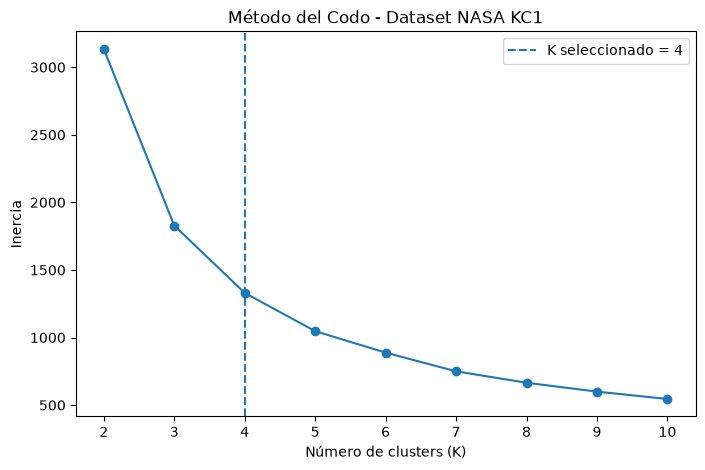

In [83]:
k_codo = 4
plt.figure(figsize=(8, 5))

plt.plot(
    resultados["K"],
    resultados["Inercia"],
    marker="o"
)

plt.axvline(
    k_codo,
    linestyle="--",
    label=f"K seleccionado = {k_codo}"
)

plt.xticks(resultados["K"])
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del Codo - Dataset NASA KC1")
plt.legend()
plt.show()

***Silhouette Score***

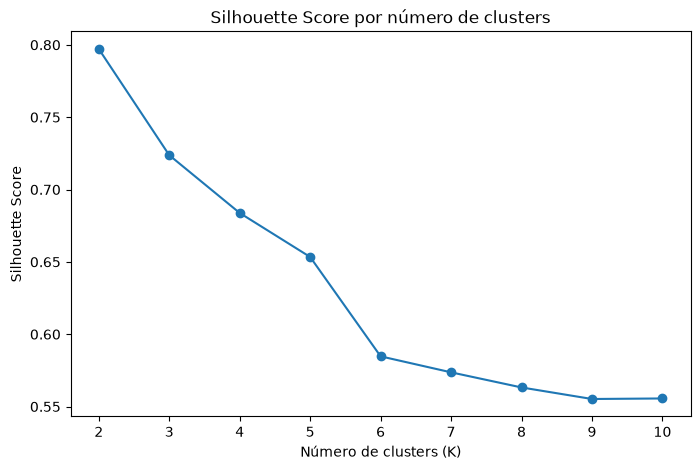

In [84]:
plt.figure(figsize=(8, 5))

plt.plot(
    resultados["K"],
    resultados["Silhouette"],
    marker="o"
)

plt.xticks(resultados["K"])
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score por número de clusters")
plt.show()

***Davies-Bouldin Index***

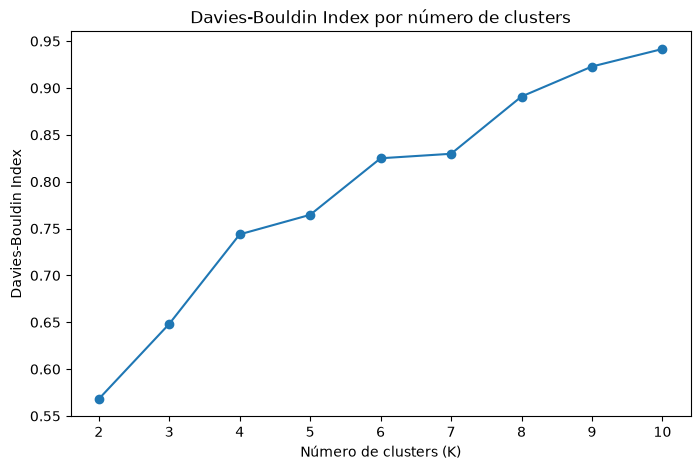

In [85]:
plt.figure(figsize=(8, 5))

plt.plot(
    resultados["K"],
    resultados["Davies-Bouldin"],
    marker="o"
)

plt.xticks(resultados["K"])
plt.xlabel("Número de clusters (K)")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index por número de clusters")
plt.show()

***Calinski-Harabasz***

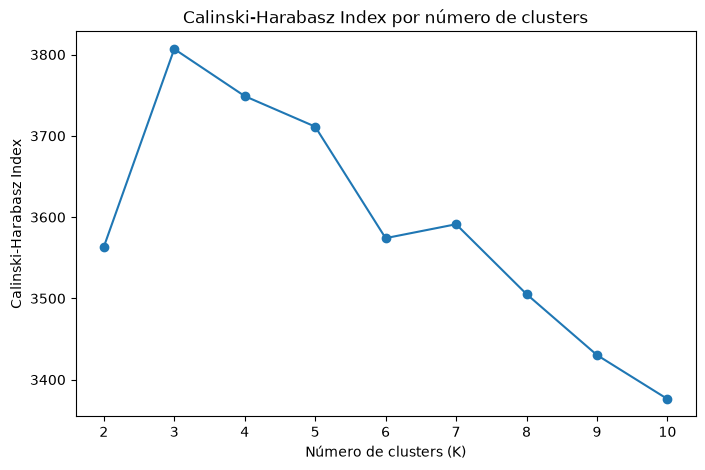

In [86]:
plt.figure(figsize=(8, 5))

plt.plot(
    resultados["K"],
    resultados["Calinski-Harabasz"],
    marker="o"
)

plt.xticks(resultados["K"])
plt.xlabel("Número de clusters (K)")
plt.ylabel("Calinski-Harabasz Index")
plt.title("Calinski-Harabasz Index por número de clusters")
plt.show()


***Comparacion entre metricas***

In [87]:
mejor_silhouette = resultados.loc[resultados["Silhouette"].idxmax(), "K"]
mejor_davies = resultados.loc[resultados["Davies-Bouldin"].idxmin(), "K"]
mejor_calinski = resultados.loc[resultados["Calinski-Harabasz"].idxmax(), "K"]
k_codo = 4

print("Mejor K según Silhouette Score:", mejor_silhouette)
print("Mejor K según Davies-Bouldin Index:", mejor_davies)
print("Mejor K según Calinski-Harabasz Index:", mejor_calinski)

print()
print("Métricas obtenidas para K =", k_codo)
print(
    resultados.loc[
        resultados["K"] == k_codo,
        ["K", "Inercia", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]
    ].round(3)
)


Mejor K según Silhouette Score: 2
Mejor K según Davies-Bouldin Index: 2
Mejor K según Calinski-Harabasz Index: 3

Métricas obtenidas para K = 4
   K   Inercia  Silhouette  Davies-Bouldin  Calinski-Harabasz
2  4  1329.998       0.684           0.744           3748.913


In [88]:
kmeans_final = KMeans(
    n_clusters=k_codo,
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(X_scaled)

df_resultado = df.loc[df_x.index].copy()
df_resultado["Cluster"] = clusters

print("Cantidad de módulos por cluster:")
display(
    df_resultado["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Módulos")
    .to_frame()
)

print("Promedio de las métricas por cluster:")
display(
    df_resultado
    .groupby("Cluster")[variables]
    .mean()
    .round(2)
)

Cantidad de módulos por cluster:


,Módulos
Cluster,
0,311
1,1644
2,120
3,34


Promedio de las métricas por cluster:


,loc,v(g),v,iv(g)
Cluster,,,,
0,42.74,5.09,573.31,4.44
1,8.58,1.35,65.86,1.28
2,83.72,11.86,1339.19,10.39
3,162.41,22.26,2891.46,18.82


### Parte 4. Análisis e interpretación

#### Pregunta 1
**¿En qué valor de K considera que aparece el "codo"? Justifique su respuesta utilizando evidencia obtenida del análisis.**

El codo se observa aproximadamente en **K = 4**. La inercia disminuye de **3134.673 en K = 2** a **1827.878 en K = 3** y luego a **1329.998 en K = 4**. A partir de K = 4, la inercia va disminuyendo, por ejemplo, **1047.195 en K = 5** y **888.216 en K = 6**. Esto indica que después de cuatro clusters el beneficio de agregar nuevos grupos comienza a disminuir.

Las métricas adicionales no seleccionan exactamente el mismo valor de K: **Silhouette Score y Davies-Bouldin favorecen K = 2**, mientras que **Calinski-Harabasz favorece K = 3**. Sin embargo, guiandose del Método del Codo, **K = 4 representa un punto razonable de equilibrio entre reducción de inercia y número de clusters**.

#### Pregunta 2
**¿Por qué no resulta conveniente seleccionar valores excesivamente grandes para K?**

No resulta conveniente seleccionar valores demasiado grandes de K porque la inercia siempre disminuye al aumentar la cantidad de clusters, pero esto no significa necesariamente que el agrupamiento sea mejor. Un valor excesivo de K puede producir grupos muy pequeños, dificultar su interpretación y dividir observaciones que podrían pertenecer razonablemente al mismo grupo.

#### Pregunta 3
**¿Qué representa la inercia dentro del algoritmo K-Means?**

La inercia representa la **suma de las distancias cuadráticas de cada observación respecto al centroide del cluster al que pertenece**. Por lo tanto, mide qué tan compactos son los grupos generados por K-Means.

Una inercia menor indica que las observaciones se encuentran, en promedio, más cerca de sus respectivos centroides y que los clusters son más compactos. Sin embargo, esta métrica debe analizarse junto con otros criterios, ya que disminuye naturalmente cuando aumenta el número de clusters.

#### Pregunta 4
**¿Cómo se comporta la inercia conforme aumenta el número de grupos? Explique el fenómeno observado.**

La inercia **disminuye conforme aumenta el número de clusters**. En el experimento pasó de **3134.673 con K = 2** a **545.088 con K = 10**.

Esto sucede porque, al crear más clusters, cada observación puede ser asignada a un centroide más cercano, reduciendo las distancias internas. Sin embargo, la reducción es cada vez menor. Los primeros incrementos de K generan mejoras importantes, mientras que después de aproximadamente **K = 4** la disminución comienza a ser menos pronunciada. Este comportamiento es precisamente el que permite aplicar el Método del Codo.

#### Pregunta 5
**¿Considera que los grupos obtenidos podrían utilizarse para identificar módulos de software con características similares? Justifique su respuesta.**

Sí. Los clusters obtenidos pueden utilizarse para identificar **módulos de software con características similares**, ya que K-Means agrupa las observaciones de acuerdo con la similitud de las métricas utilizadas después de su estandarización.

Con **K = 4** se obtuvo una inercia de **1329.998**, un **Silhouette Score de 0.684**, un **Davies-Bouldin Index de 0.744** y un **Calinski-Harabasz Index de 3748.913**. El Silhouette Score de 0.684 indica una separación razonablemente buena entre los grupos. Por ello, los clusters pueden servir como apoyo para reconocer diferentes perfiles de módulos y facilitar la identificación de conjuntos de software con comportamientos o características métricas semejantes.